# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy import signal

# Global parameters
Kp_list = [2.0, 5.0, 10.0]
Kp_pi, Ki_list = 2.0, [1.0, 2.0, 4.0]
t = np.linspace(0, 20, 8000)

# Funkcije

In [2]:
s = sp.symbols("s")
Kp, Ki = sp.symbols("K_p K_i", positive=True)

def zaprta(F1, F2=1):
    # negativna povratna vezava
    return sp.cancel(F1 / (1 + F1 * F2))

def v_scipy(H):
    # sympy racionalna funkcija -> scipy TransferFunction
    num, den = sp.fraction(sp.cancel(sp.together(H)))
    n = [float(c) for c in sp.Poly(num, s).all_coeffs()]
    d = [float(c) for c in sp.Poly(den, s).all_coeffs()]
    return signal.TransferFunction(np.array(n) / d[0], np.array(d) / d[0])

def odziv(H, t=t):
    return signal.step(v_scipy(H), T=t)

def prenihaj(y):
    return 100 * max(y.max() / y[-1] - 1, 0)

In [3]:
# Numericna (polinomska) algebra blokov: blok = (stevec, imenovalec)
def mnozi(*bloki):
    n, d = np.array([1.0]), np.array([1.0])
    for bn, bd in bloki:
        n, d = np.polymul(n, bn), np.polymul(d, bd)
    return n, d

def sestej(*bloki):
    n, d = np.array([0.0]), np.array([1.0])
    for bn, bd in bloki:
        n, d = np.polyadd(np.polymul(n, bd), np.polymul(bn, d)), np.polymul(d, bd)
    return n, d

def deli(a, b):
    return np.polymul(a[0], b[1]), np.polymul(a[1], b[0])

# Testno območje

In [4]:
# Pripravljalna naloga
Fp = 1 / (s + 2)
H = zaprta(Kp * Fp)
display(sp.Eq(sp.Symbol("H(s)"), H))
E = sp.cancel((1 - H) / s)                     # E(s) = X(s) - Y(s), X = 1/s
e_stat = sp.limit(s * E, s, 0)
display(sp.Eq(sp.Symbol("e_{stat}"), e_stat))
for k in Kp_list:
    print(f"K_p = {k:4.1f}: e_stat = {float(e_stat.subs(Kp, k)):.4f}")

Eq(H(s), K_p/(K_p + s + 2))

Eq(e_{stat}, 2/(K_p + 2))

K_p =  2.0: e_stat = 0.5000
K_p =  5.0: e_stat = 0.2857
K_p = 10.0: e_stat = 0.1667


# Naloga 1

Eq(H_0(s), 10*(s + 5)/(s**5 + 15*s**4 + 85*s**3 + 230*s**2 + 306*s + 153))

poli H0: [-4.9469+0.2146j -4.9469-0.2146j -1.9745+1.2224j -1.9745-1.2224j
 -1.1571+0.j    ]
max |H_sympy - H_polinomi| = 1.9e-16


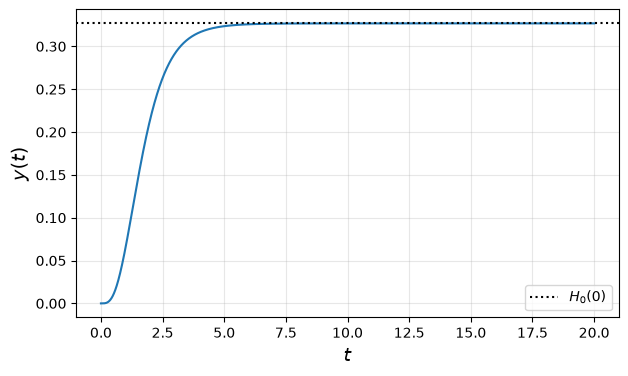

In [5]:
# Ilustrativna izbira blokov (konkretni bloki iz ucbenika niso podani)
F = {
    1: 1 / (s + 1), 2: 2 / (s + 2), 3: 1 / (s + 3), 4: 5 / (s + 4),
    5: sp.Rational(1, 2), 6: sp.Integer(1), 7: 1 / (s + 5),
}
H0 = sp.cancel(F[1] * F[2] * F[3] * F[4] / (1 + F[2] * F[3] * F[4] * F[5] + F[1] * F[2] * F[3] * F[6] * F[7]))
display(sp.Eq(sp.Symbol("H_0(s)"), sp.factor(H0)))
H0_tf = v_scipy(H0)
print("poli H0:", np.round(H0_tf.poles, 4))

# isto s polinomsko algebro
B = {k: (np.array([float(c) for c in sp.Poly(sp.fraction(sp.together(v))[0], s).all_coeffs()]),
         np.array([float(c) for c in sp.Poly(sp.fraction(sp.together(v))[1], s).all_coeffs()])) for k, v in F.items()}
stev = mnozi(B[1], B[2], B[3], B[4])
imen = sestej((np.array([1.0]), np.array([1.0])), mnozi(B[2], B[3], B[4], B[5]), mnozi(B[1], B[2], B[3], B[6], B[7]))
n_num, d_num = deli(stev, imen)
w = np.logspace(-1, 2, 50)
_, h_sym = signal.freqs(H0_tf.num, H0_tf.den, w)
_, h_num = signal.freqs(n_num, d_num, w)
print(f"max |H_sympy - H_polinomi| = {np.max(np.abs(h_sym - h_num)):.1e}")

t_, y = signal.step(H0_tf, T=t)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.plot(t_, y)
ax.axhline(float(H0.subs(s, 0)), color="black", linestyle=":", label=r"$H_0(0)$")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$y(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Naloga 2

P regulacija:
  K_p =  2.0: y(inf) = 0.6667, e_stat = 0.3333 (teorija 0.3333), prenihaj = 8.8 %
  K_p =  5.0: y(inf) = 0.8333, e_stat = 0.1667 (teorija 0.1667), prenihaj = 22.1 %
  K_p = 10.0: y(inf) = 0.9091, e_stat = 0.0909 (teorija 0.0909), prenihaj = 34.6 %
PI regulacija:
  K_p = 2.0, K_i = 1.0: y(t_end) = 0.9999, prenihaj = 0.0 %
  K_p = 2.0, K_i = 2.0: y(t_end) = 1.0000, prenihaj = 16.3 %
  K_p = 2.0, K_i = 4.0: y(t_end) = 1.0000, prenihaj = 44.4 %


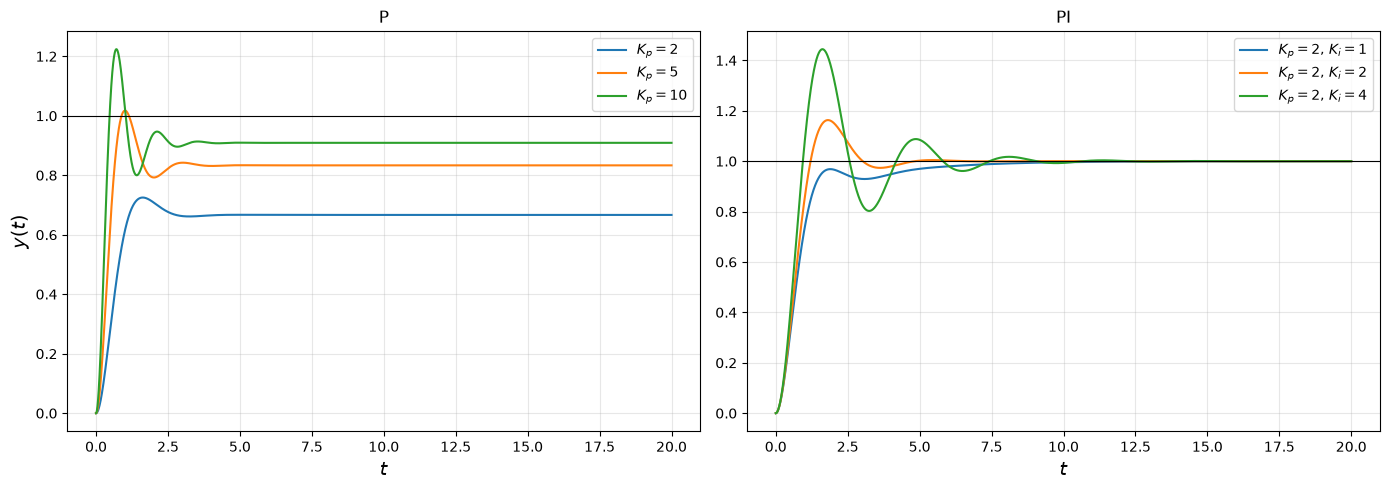

In [6]:
Fp2 = 2 / (s**2 + 3 * s + 2)

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(121)
print("P regulacija:")
for k in Kp_list:
    t_, y = odziv(zaprta(k * Fp2))
    ax.plot(t_, y, label=f"$K_p = {k:.0f}$")
    print(f"  K_p = {k:4.1f}: y(inf) = {y[-1]:.4f}, e_stat = {1 - y[-1]:.4f} (teorija {1 / (1 + k):.4f}), prenihaj = {prenihaj(y):.1f} %")
ax.axhline(1, color="black", linewidth=0.8)
ax.set_title("P")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$y(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)

ax = fig.add_subplot(122)
print("PI regulacija:")
for ki in Ki_list:
    t_, y = odziv(zaprta((Kp_pi + ki / s) * Fp2))
    ax.plot(t_, y, label=f"$K_p = {Kp_pi:.0f}$, $K_i = {ki:.0f}$")
    print(f"  K_p = {Kp_pi}, K_i = {ki}: y(t_end) = {y[-1]:.4f}, prenihaj = {prenihaj(y):.1f} %")
ax.axhline(1, color="black", linewidth=0.8)
ax.set_title("PI")
ax.set_xlabel("$t$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 3

Eq(2*K_p + s**2 + 3*s + 2, 0)

Eq(10*K_p + s**3 + 3*s**2 + s*(2*K_p + 2), 0)

meja stabilnosti PI: K_p = [3/2]


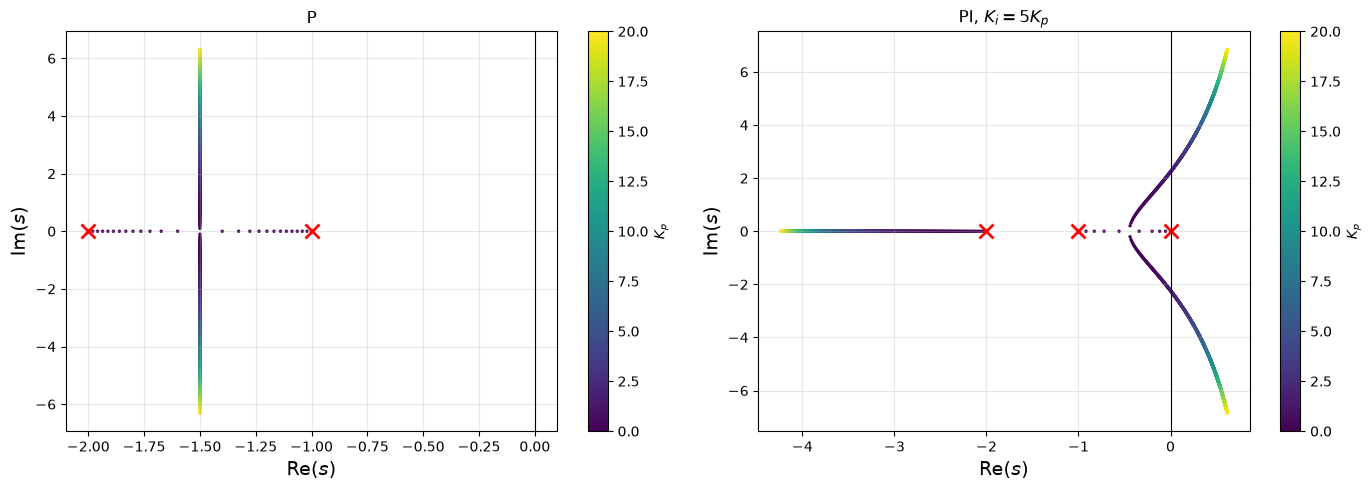

In [7]:
# Trajektorija korenov: P (2. red) in PI z nicloj pri s = -5 (K_i = 5 K_p, 3. red)
Kp_os = np.linspace(0, 20, 2001)
kar_P = sp.Poly(sp.fraction(sp.together(1 + Kp * Fp2))[0], s)
kar_PI = sp.Poly(sp.fraction(sp.together(1 + Kp * (1 + 5 / s) * Fp2))[0], s)
display(sp.Eq(kar_P.as_expr(), 0), sp.Eq(kar_PI.as_expr(), 0))

# meja stabilnosti PI (Routh-Hurwitz za a3 s^3 + a2 s^2 + a1 s + a0: a2 a1 > a3 a0)
a3, a2, a1, a0 = kar_PI.all_coeffs()
Kp_krit = sp.solve(sp.Eq(a2 * a1, a3 * a0), Kp)
print("meja stabilnosti PI: K_p =", Kp_krit)

fig = plt.figure(figsize=(14, 5))
for i, (kar, ime) in enumerate([(kar_P, "P"), (kar_PI, r"PI, $K_i = 5K_p$")]):
    koef = sp.lambdify(Kp, kar.all_coeffs(), "numpy")
    poli = np.array([np.roots(np.array(koef(k), dtype=float)) for k in Kp_os])
    ax = fig.add_subplot(1, 2, i + 1)
    sc = ax.scatter(poli.real.ravel(), poli.imag.ravel(), c=np.repeat(Kp_os, poli.shape[1]), s=2, cmap="viridis")
    ax.plot(poli[0].real, poli[0].imag, "x", color="red", markersize=10, mew=2)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel(r"Re$(s)$", fontsize=14)
    ax.set_ylabel(r"Im$(s)$", fontsize=14)
    ax.set_title(ime)
    ax.grid(alpha=0.3)
    fig.colorbar(sc, ax=ax, label="$K_p$")
plt.tight_layout()
plt.show()

# Razmislek 1

In [8]:
# Izrek o koncni vrednosti s PI: pol v s = 0 v odprti zanki -> L(0) = inf -> e_stat = 0
L = (Kp + Ki / s) * Fp2
e_PI = sp.limit(s * (1 / (1 + L)) * (1 / s), s, 0)
display(sp.Eq(sp.Symbol("e_{stat,PI}"), e_PI))

Eq(e_{stat,PI}, 0)

# Razmislek 2

K_p = 0.5: poli = [-2.618 -0.382]
K_p = 0.9: poli = [-2.932 -0.068]
K_p = 1.5: poli = [-3.303  0.303]


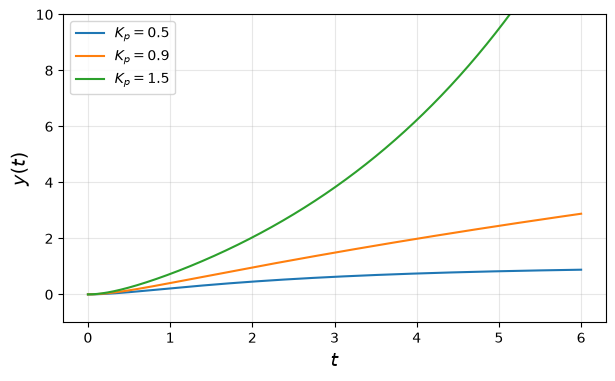

In [9]:
# Pozitivna povratna vezava: H = F1 / (1 - F1 F2)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for k in [0.5, 0.9, 1.5]:
    H_poz = sp.cancel(k * Fp2 / (1 - k * Fp2))
    tf = v_scipy(H_poz)
    t_, y = signal.step(tf, T=np.linspace(0, 6, 2000))
    ax.plot(t_, y, label=f"$K_p = {k}$")
    print(f"K_p = {k}: poli = {np.round(tf.poles, 3)}")
ax.set_ylim(-1, 10)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel("$y(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()